## Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
        

Levando em conta a base de dados **_Dry Bean Dataset_**, esta segunda parte do Projeto Prático 2.2 diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo Feedforward Multilayer Perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Testando Redes Neurais com os Atributos Numéricos

1. Abra a base de dados em questão
2. Verifique que todos os atributos preditores são numéricos. O único atributo categórico é o alvo (`Class`), que não deve entrar em X
3. Armazene o atributo alvo em uma variável y e os atributos preditores em uma variável X
4. Efetue uma partição holdout 70/30 com o sklearn, distribuindo os exemplos de maneira aleatória e estratificada (`stratify=y`), com `random_state` fixo para reprodutibilidade
5. Efetue o escalonamento dos atributos


In [36]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import classification_report
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score
)

import matplotlib.pyplot as plt

In [3]:
df = pd.read_excel('Dry_Bean_Dataset.xlsx')

In [4]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

In [5]:
y = df["Class"]
y.head()

0    SEKER
1    SEKER
2    SEKER
3    SEKER
4    SEKER
Name: Class, dtype: str

In [6]:
X = df.drop("Class", axis=1)
X.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=64,
    stratify=y
)

### Escalonando os atributos

O treinamento de uma rede neural artificial é mais eficiente quando os valores que lhes são fornecidos como entrada são pequenos e estão em escalas semelhantes, pois isto favorece a convergência. Isto é feito escalonando-se os atributos, mas precisa ser feito de maneira cautelosa, para que informações do conjunto de teste não sejam fornecidas no treinamento.

Há duas estratégias para tal escalonamento: normalização (que leva os valores ao intervalo [0,1]) e padronização (que centraliza os dados em média 0 e desvio padrão 1). Ambas possuem características particulares, vantagens e limitações, como é possível ver aqui: https://www.analyticsvidhya.com/blog/2020/04/feature-scaling-machine-learning-normalization-standardization/

No nosso caso, vamos usar a padronização. Assim, com os atributos preditores do treinamento, isto é, X_train, deve-se subtrair a média e dividir pelo desvio padrão. Para tanto, use o StandardScaler e ajuste-o com os dados do conjunto de treino (fit), transformando-os em seguida (transform). Depois, apenas transforme os dados do conjunto de teste (transform), usando a média e o desvio padrão calculados no treino, sem chamar o fit novamente.

Se todo o conjunto X for utilizado na padronização, a rede neural receberá informações do conjunto de teste por meio da média e do desvio padrão utilizados para preparar os dados de treinamento, o que não é desejável (vazamento de dados, ou *data leakage*).

In [19]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

### Continuando

1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios  
    1.1 Utilize a função de ativação ReLU  
    1.2 Utilize o solver Adam    
    1.3 Imprima o passo a passo do treinamento  
    1.4 Utilize o número máximo de épocas igual a 300
2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:  
    2.1 Matriz de confusão  
    2.2 Acurácia  
    2.3 F-Score (F1)  
    2.4 Precisão  
    2.5 Revocação   
3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes  
    3.1 Cada uma destas repetições deve ser feita com uma nova partição holdout 70/30 estratificada, e o escalonamento deve ser reajustado com os dados de treino de cada partição  
    3.2 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
4. Repita por 10 vezes o treinamento desta mesma rede, mas utilizando o otimizador SGD, com as mesmas 10 partições do item anterior  
    4.1 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
5. Houve influência da escolha do otimizador no desempenho da rede? Justifique com as médias e os desvios padrão obtidos

### **1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios**

In [22]:
mlp = MLPClassifier(
    hidden_layer_sizes=(10),
    activation="relu",
    solver="adam",
    max_iter=300,
    verbose=True
)

In [23]:
mlp.fit(X_train, y_train)

Iteration 1, loss = 1.59839202
Iteration 2, loss = 1.25195160
Iteration 3, loss = 1.02622617
Iteration 4, loss = 0.86971799
Iteration 5, loss = 0.75907816
Iteration 6, loss = 0.67406750
Iteration 7, loss = 0.60452327
Iteration 8, loss = 0.54640971
Iteration 9, loss = 0.49724456
Iteration 10, loss = 0.45550927
Iteration 11, loss = 0.42046852
Iteration 12, loss = 0.39160604
Iteration 13, loss = 0.36669149
Iteration 14, loss = 0.34638315
Iteration 15, loss = 0.32908500
Iteration 16, loss = 0.31452551
Iteration 17, loss = 0.30221413
Iteration 18, loss = 0.29148643
Iteration 19, loss = 0.28238324
Iteration 20, loss = 0.27437706
Iteration 21, loss = 0.26727003
Iteration 22, loss = 0.26121313
Iteration 23, loss = 0.25582728
Iteration 24, loss = 0.25111855
Iteration 25, loss = 0.24694162
Iteration 26, loss = 0.24335030
Iteration 27, loss = 0.24028030
Iteration 28, loss = 0.23714973
Iteration 29, loss = 0.23476420
Iteration 30, loss = 0.23209562
Iteration 31, loss = 0.22993747
Iteration 32, los

/home/amazonas_matheus/Projeto-Pratico-2.2/venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.",10
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


### **2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:**

In [24]:
y_pred = mlp.predict(X_test)

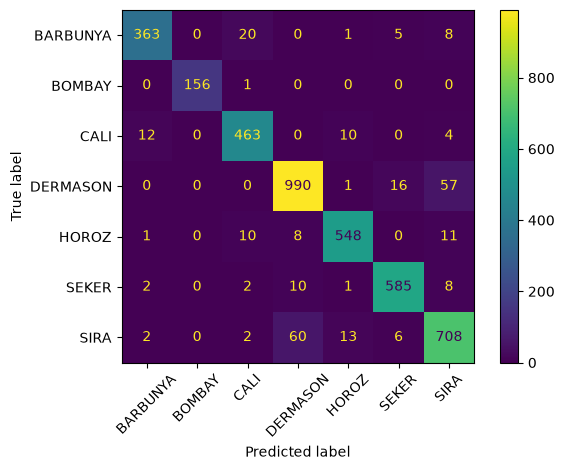

In [25]:
cm = confusion_matrix(y_test, y_pred, labels=mlp.classes_)
ConfusionMatrixDisplay(cm, display_labels=mlp.classes_).plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [26]:
acc = accuracy_score(y_test, y_pred)
print(f"Acurácia:  {acc:.4f}")

Acurácia:  0.9336


In [27]:
f1 = f1_score(y_test, y_pred, average="macro")
print(f"F1:        {f1:.4f}")

F1:        0.9430


In [28]:
prec = precision_score(y_test, y_pred, average="macro")
print(f"Precisão:  {prec:.4f}")

Precisão:  0.9446


In [29]:
rec = recall_score(y_test, y_pred, average="macro")
print(f"Revocação: {rec:.4f}")

Revocação: 0.9415


### **3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes**

In [32]:
acuracias = []
f1s = []

In [34]:
for i in range(10):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=64
    )
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    mlp2 = MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="relu",
        solver="adam",
        max_iter=300,
        verbose=False
    )
    mlp2.fit(X_train_s, y_train)
    y_pred = mlp.predict(X_test_s)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    acuracias.append(acc)
    f1s.append(f1)

/home/amazonas_matheus/Projeto-Pratico-2.2/venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/amazonas_matheus/Projeto-Pratico-2.2/venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [39]:
print(f"Acurácia: {np.mean(acuracias):.4f} ± {np.std(acuracias):.4f}")
print(f"F1 (macro): {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")

Acurácia: 0.9336 ± 0.0000
F1 (macro): 0.9430 ± 0.0000


## Discussão

Nos passos anteriores, você avaliou o desempenho de uma única arquitetura de rede neural, com uma única camada oculta de 10 neurônios e função de ativação ReLU. O otimizador utilizado, seja o SGD ou o Adam, é o algoritmo que usa o gradiente do erro (calculado pela retropropagação) para atualizar os pesos da rede. Neste sentido, a escolha do otimizador é um hiperparâmetro: ela é definida antes do treinamento, não é aprendida a partir dos dados e controla como a rede será treinada. Também são hiperparâmetros a quantidade de camadas ocultas, o número de neurônios, a função de ativação, a quantidade de épocas, a taxa de aprendizado inicial, dentre outros. Já os parâmetros da rede são os pesos e os vieses, ajustados durante o treinamento.

Cabe salientar também que você efetuou o treinamento desta rede por 10 vezes e apresentou os resultados em termos de média ± desvio padrão. Lembre-se que em uma rede neural há a inicialização aleatória de pesos e, em consequência, o desempenho está sujeito a uma flutuação estocástica. Além disso, cada repetição utilizou uma nova partição holdout, o que introduz uma segunda fonte de variação. A execução múltipla das repetições reduz a influência de uma boa ou má "sorte" na escolha dos pesos iniciais e da partição, que poderia distorcer a conclusão no caso de uma única execução, e permite estimar a variabilidade do desempenho por meio do desvio padrão.

Você também aprendeu uma estratégia para escalonar os atributos para uma melhor convergência da rede. Utilize-a em todos os treinamentos e testes propostos a seguir.

## Propondo Novas Arquiteturas

Variando a arquitetura da rede (uma ou duas camadas ocultas, com diferentes números de neurônios em cada uma delas, e a função de ativação) e os hiperparâmetros solver (Adam ou SGD) e número máximo de épocas (100, 150 e 200), atenda ao que se pede:

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha
2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  
    2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa  
    2.2 Ao todo, serão 60 configurações (10 arquiteturas × 2 solvers × 3 números de épocas) e 600 treinamentos
3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  
    3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha

In [57]:
# me disseram pra colocar isso e tiraria os warnings de não convergencia
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [58]:
arquiteturas = {
    "N1: (10) relu":         ((10,), "relu"),
    "N2: (32) relu":         ((32,), "relu"),
    "N3: (32) tanh":         ((32,), "tanh"),
    "N4: (32) logistic":     ((32,), "logistic"),
    "N5: (64) logistic":     ((64,), "logistic"),
    "N6: (16,8) relu":       ((16, 8), "relu"),
    "N7: (32,16) relu":      ((32, 16), "relu"),
    "N8: (32,16) tanh":      ((32,16), "tanh"),
    "N9: (32,16) logistic":  ((32, 16), "logistic"),
    "N10: (32) identity":    ((32,), "identity"),
}

2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  

In [59]:
solvers = ["adam", "sgd"]

In [60]:
epocas = [100, 200, 300]

In [61]:
REP = 10

In [62]:
particoes = []

2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa 

In [63]:
for i in range(REP):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=64
    )
    scaler = StandardScaler()                 
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)
    particoes.append((X_tr_s, X_te_s, y_tr, y_te))

In [64]:
classes = sorted(y.unique())

In [65]:
resultados = {}

In [66]:
for nome, (camadas, ativ) in arquiteturas.items():
    for solver in solvers:
        for n_ep in epocas:
            reps = []
            for i, (X_tr_s, X_te_s, y_tr, y_te) in enumerate(particoes):
                mlp3 = MLPClassifier(
                    hidden_layer_sizes=camadas,
                    activation=ativ,
                    solver=solver,
                    max_iter=n_ep,
                    random_state=i,
                    verbose=False,
                )
                mlp3.fit(X_tr_s, y_tr)
                y_pred = mlp.predict(X_te_s)
                reps.append({
                    "acc": accuracy_score(y_te, y_pred),
                    "f1": f1_score(y_te, y_pred, average="macro", zero_division=0),
                    "y_te": y_te,
                    "y_pred": y_pred,
                })
            resultados[(nome, solver, n_ep)] = reps
            print(f"{nome} | {solver} | {n_ep} épocas")

OK: N1: (10) relu | adam | 100 epochs
OK: N1: (10) relu | adam | 200 epochs
OK: N1: (10) relu | adam | 300 epochs
OK: N1: (10) relu | sgd | 100 epochs
OK: N1: (10) relu | sgd | 200 epochs
OK: N1: (10) relu | sgd | 300 epochs
OK: N2: (32) relu | adam | 100 epochs
OK: N2: (32) relu | adam | 200 epochs
OK: N2: (32) relu | adam | 300 epochs
OK: N2: (32) relu | sgd | 100 epochs
OK: N2: (32) relu | sgd | 200 epochs
OK: N2: (32) relu | sgd | 300 epochs
OK: N3: (32) tanh | adam | 100 epochs
OK: N3: (32) tanh | adam | 200 epochs
OK: N3: (32) tanh | adam | 300 epochs
OK: N3: (32) tanh | sgd | 100 epochs
OK: N3: (32) tanh | sgd | 200 epochs
OK: N3: (32) tanh | sgd | 300 epochs
OK: N4: (32) logistic | adam | 100 epochs
OK: N4: (32) logistic | adam | 200 epochs
OK: N4: (32) logistic | adam | 300 epochs
OK: N4: (32) logistic | sgd | 100 epochs
OK: N4: (32) logistic | sgd | 200 epochs
OK: N4: (32) logistic | sgd | 300 epochs
OK: N5: (64) logistic | adam | 100 epochs
OK: N5: (64) logistic | adam | 200

In [67]:
linhas = []
for (nome, solver, n_ep), reps in resultados.items():
    accs = pd.Series([r["acc"] for r in reps])
    f1s = pd.Series([r["f1"] for r in reps])
    linhas.append({
        "arquitetura": nome, "solver": solver, "épocas": n_ep,
        "acc_média": accs.mean(), "acc_std": accs.std(ddof=1),
        "f1_média": f1s.mean(), "f1_std": f1s.std(ddof=1),
    })
df = pd.DataFrame(linhas)

3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  

In [68]:
top_f1 = df.sort_values("f1_média", ascending=False).head(3)
top_acc = df.sort_values("acc_média", ascending=False).head(3)

def mostra(top, titulo):
    print(f"\n=== {titulo} ===")
    for _, r in top.iterrows():
        print(f"{r['arquitetura']} | {r['solver']} | {r['épocas']} ép. -> "
              f"F1 = {r['f1_média']:.4f} ± {r['f1_std']:.4f} | "
              f"Acc = {r['acc_média']:.4f} ± {r['acc_std']:.4f}")

mostra(top_f1, "Top 3 por F1 macro")
mostra(top_acc, "Top 3 por acurácia")



=== Top 3 por F1 macro ===
N1: (10) relu | adam | 100 ép. -> F1 = 0.9430 ± 0.0000 | Acc = 0.9336 ± 0.0000
N1: (10) relu | adam | 200 ép. -> F1 = 0.9430 ± 0.0000 | Acc = 0.9336 ± 0.0000
N1: (10) relu | adam | 300 ép. -> F1 = 0.9430 ± 0.0000 | Acc = 0.9336 ± 0.0000

=== Top 3 por acurácia ===
N1: (10) relu | adam | 100 ép. -> F1 = 0.9430 ± 0.0000 | Acc = 0.9336 ± 0.0000
N1: (10) relu | adam | 200 ép. -> F1 = 0.9430 ± 0.0000 | Acc = 0.9336 ± 0.0000
N1: (10) relu | adam | 300 ép. -> F1 = 0.9430 ± 0.0000 | Acc = 0.9336 ± 0.0000


3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

In [69]:
def detalha(top, titulo):
    print(f"\n##### {titulo} #####")
    for _, r in top.iterrows():
        chave = (r["arquitetura"], r["solver"], r["épocas"])
        reps = resultados[chave]
        melhor = max(range(N_REP), key=lambda k: reps[k]["f1"])
        rep = reps[melhor]

        cm = confusion_matrix(rep["y_te"], rep["y_pred"], labels=classes)
        print(f"\n{chave} | melhor repetição = {melhor + 1} "
              f"(F1 = {rep['f1']:.4f}, Acc = {rep['acc']:.4f})")
        print(pd.DataFrame(cm, index=classes, columns=classes))

        total = cm.sum()
        VP = cm.diagonal()
        FP = cm.sum(axis=0) - VP
        FN = cm.sum(axis=1) - VP
        VN = total - VP - FP - FN
        print(pd.DataFrame({"VP": VP, "VN": VN, "FP": FP, "FN": FN}, index=classes))

In [70]:
detalha(top_f1, "Detalhe: top 3 por F1")
detalha(top_acc, "Detalhe: top 3 por acurácia")


##### Detalhe: top 3 por F1 #####

('N1: (10) relu', 'adam', 100) | melhor repetição = 1 (F1 = 0.9430, Acc = 0.9336)
          BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
BARBUNYA       363       0    20         0      1      5     8
BOMBAY           0     156     1         0      0      0     0
CALI            12       0   463         0     10      0     4
DERMASON         0       0     0       990      1     16    57
HOROZ            1       0    10         8    548      0    11
SEKER            2       0     2        10      1    585     8
SIRA             2       0     2        60     13      6   708
           VP    VN  FP  FN
BARBUNYA  363  3670  17  34
BOMBAY    156  3927   0   1
CALI      463  3560  35  26
DERMASON  990  2942  78  74
HOROZ     548  3480  26  30
SEKER     585  3449  27  23
SIRA      708  3205  88  83

('N1: (10) relu', 'adam', 200) | melhor repetição = 1 (F1 = 0.9430, Acc = 0.9336)
          BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
BARBUNYA

## Estimando o número de neurônios

Um dos problemas de pesquisa com redes neurais artificiais consiste na determinação do número de neurônios em sua arquitetura. Embora não seja possível definir a priori qual rede neural é adequada para um problema, pois isto só pode ser determinado empiricamente, mediante a avaliação de várias arquiteturas, há regras na literatura que sugerem o número de neurônios escondidos, tal como a regra da Pirâmide Geométrica, dada a seguir:

$$N_h = \alpha \cdot \sqrt{N_i \cdot N_o},$$

em que $N_h$ é o número de neurônios ocultos (a serem distribuídos em uma ou duas camadas ocultas), $N_i$ é o número de neurônios na camada de entrada e $N_o$ é o número de neurônios na camada de saída. Como $N_h$ deve ser um número inteiro, arredonde o resultado para o inteiro mais próximo.

1. Consulte a documentação da classe MLPClassifier (disponível em https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) e obtenha os valores de $N_i$ e $N_o$ para a base _Dry Bean_, considerando o número de atributos preditores e o número de classes do problema.
2. Teste os valores de $\alpha$ como sendo iguais a $0.5$, $2$ e $3$.
3. Proponha pelo menos 30 redes neurais segundo a regra da pirâmide geométrica e teste-as nos mesmos termos estabelecidos anteriormente (solver, épocas, 10 repetições com as mesmas partições holdout, escalonamento, etc.)  
    3.1 Apresente as top-3 melhores redes no tocante à F-Score e Acurácia, com base no conjunto de teste

### Respostas

Na documentação, na seção de atributos, dois itens são úteis para a resposta:  
- n_features_in_: número de features vistas durante o fit.
- n_outputs_: número de neurônios na camada de saída

Logo, são Ni (número de entradas, ou seja, número de atributos preditores) e No (número de saídas, ou seja o número de classes) respectivamente.

In [74]:
# Testando alphas
Ni, No = 16, 7
alphas = [0.5, 2, 3]

In [73]:
for alpha in alphas:
    Nh = round(alpha* (Ni * No) ** 0.5)
    print(f"a = {alpha} -> Nh = {Nh}")

a = 0.5 -> Nh = 5
a = 2 -> Nh = 21
a = 3 -> Nh = 32


A regra da pirâmide geométrica (proposta por Timothy Masters em 1993) é uma heurística empírica usada para definir a quantidade ideal de neurônios nas camadas ocultas de uma rede neural artificial (especialmente em redes Multilayer Perceptron - MLP).

In [75]:
arq_piramide = {}
for alpha in alphas:
    Nh = round(alpha * (Ni * No) ** 0.5)

    formatos = {
        "1c":      (Nh,),
        "2c 75/25": (round(Nh * 0.75), Nh - round(Nh * 0.75)),
        "2c 50/50": (round(Nh * 0.50), Nh - round(Nh * 0.50)),
        "2c 25/75": (round(Nh * 0.25), Nh - round(Nh * 0.25)),
    }

    for nome_f, camadas in formatos.items():
        for ativ in ["relu", "tanh"]:
            arq_piramide[f"α={alpha} Nh={Nh} {nome_f} {camadas} {ativ}"] = (camadas, ativ)

    arq_piramide[f"α={alpha} Nh={Nh} 1c {formatos['1c']} logistic"] = (formatos["1c"], "logistic")
    arq_piramide[f"α={alpha} Nh={Nh} 2c 50/50 {formatos['2c 50/50']} logistic"] = (formatos["2c 50/50"], "logistic")

In [76]:
print(len(arq_piramide), "redes") 
for nome, (camadas, ativ) in arq_piramide.items():
    print(nome)

30 redes
α=0.5 Nh=5 1c (5,) relu
α=0.5 Nh=5 1c (5,) tanh
α=0.5 Nh=5 2c 75/25 (4, 1) relu
α=0.5 Nh=5 2c 75/25 (4, 1) tanh
α=0.5 Nh=5 2c 50/50 (2, 3) relu
α=0.5 Nh=5 2c 50/50 (2, 3) tanh
α=0.5 Nh=5 2c 25/75 (1, 4) relu
α=0.5 Nh=5 2c 25/75 (1, 4) tanh
α=0.5 Nh=5 1c (5,) logistic
α=0.5 Nh=5 2c 50/50 (2, 3) logistic
α=2 Nh=21 1c (21,) relu
α=2 Nh=21 1c (21,) tanh
α=2 Nh=21 2c 75/25 (16, 5) relu
α=2 Nh=21 2c 75/25 (16, 5) tanh
α=2 Nh=21 2c 50/50 (10, 11) relu
α=2 Nh=21 2c 50/50 (10, 11) tanh
α=2 Nh=21 2c 25/75 (5, 16) relu
α=2 Nh=21 2c 25/75 (5, 16) tanh
α=2 Nh=21 1c (21,) logistic
α=2 Nh=21 2c 50/50 (10, 11) logistic
α=3 Nh=32 1c (32,) relu
α=3 Nh=32 1c (32,) tanh
α=3 Nh=32 2c 75/25 (24, 8) relu
α=3 Nh=32 2c 75/25 (24, 8) tanh
α=3 Nh=32 2c 50/50 (16, 16) relu
α=3 Nh=32 2c 50/50 (16, 16) tanh
α=3 Nh=32 2c 25/75 (8, 24) relu
α=3 Nh=32 2c 25/75 (8, 24) tanh
α=3 Nh=32 1c (32,) logistic
α=3 Nh=32 2c 50/50 (16, 16) logistic


## Considerações Parciais

1. É possível identificar uma rede com desempenho superior às demais? 
2. Qual estratégia mostrou-se mais produtiva para a obtenção de boas arquiteturas (Estratégia Própria ou Pirâmide Geométrica)? Por quê?
3. Um número maior de épocas trouxe melhorias? Justifique com os resultados obtidos, considerando também cada um dos solvers (Adam e SGD)
4. Qual a maior dificuldade de resolução do problema proposto perante as RNAs?